# 01 · From a hand to 63 numbers

How one camera frame becomes the input of the letter model, using only data that ships with the repo
(my recorded sessions store the raw hand points MediaPipe found, so no webcam is needed here).

Pipeline: **MediaPipe finds 21 hand points → convert to pixels → normalize (position, size, which hand) → 63 numbers.**
See `docs/journal/01-setup-capture-landmarks-features.md` for the full story.

In [1]:
%matplotlib inline
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
os.chdir(ROOT)                       # paths below are relative to the repo root
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 110

In [2]:
from aslcv.landmarks import CONNECTIONS
from aslcv.features import normalize_landmarks

s4 = np.load("data/recorded/20261011-020828.npz")      # session 4 saved raw pixel landmarks
print("arrays in the file:", s4.files)
raw = s4["raw"][s4["y"] == "L"][40]                     # one frame of my hand signing L
print("one raw hand:", raw.shape, "(21 points x [x px, y px, depth])")

arrays in the file: ['X', 'y', 'session', 'raw', 'model_hand']
one raw hand: (21, 3) (21 points x [x px, y px, depth])


## The 21 points

Wrist (0), then four points per finger: thumb 1–4, index 5–8, middle 9–12, ring 13–16, pinky 17–20.

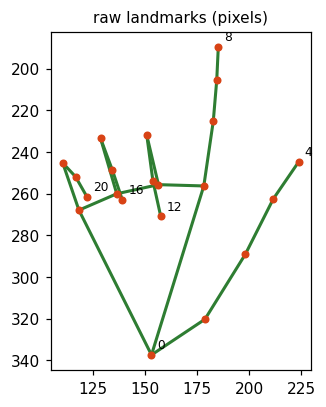

In [3]:
def draw(ax, pts, title, flip_y=True):
    for a, b in CONNECTIONS:
        ax.plot(pts[[a, b], 0], pts[[a, b], 1], "-", color="#2e7d32", lw=2)
    ax.scatter(pts[:, 0], pts[:, 1], s=18, c="#d84315", zorder=3)
    for i in (0, 4, 8, 12, 16, 20):
        ax.annotate(str(i), pts[i, :2], textcoords="offset points", xytext=(4, 4), fontsize=8)
    if flip_y: ax.invert_yaxis()                          # image y grows downward
    ax.set_aspect("equal"); ax.set_title(title, fontsize=10)

fig, ax = plt.subplots(figsize=(4, 4))
draw(ax, raw, "raw landmarks (pixels)")
plt.show()

## Normalization: keep only the shape

1. mirror left hands (`handedness="Left"`), so one model serves both hands,
2. move the wrist to (0, 0, 0): position in the frame no longer matters,
3. divide by the wrist → middle-knuckle distance: size / distance to the camera no longer matter.

63 numbers, first 9: [ 0.     0.     0.     0.312 -0.208 -0.148  0.549 -0.589 -0.208]
wrist: [0. 0. 0.] | wrist->middle knuckle length: 1.0


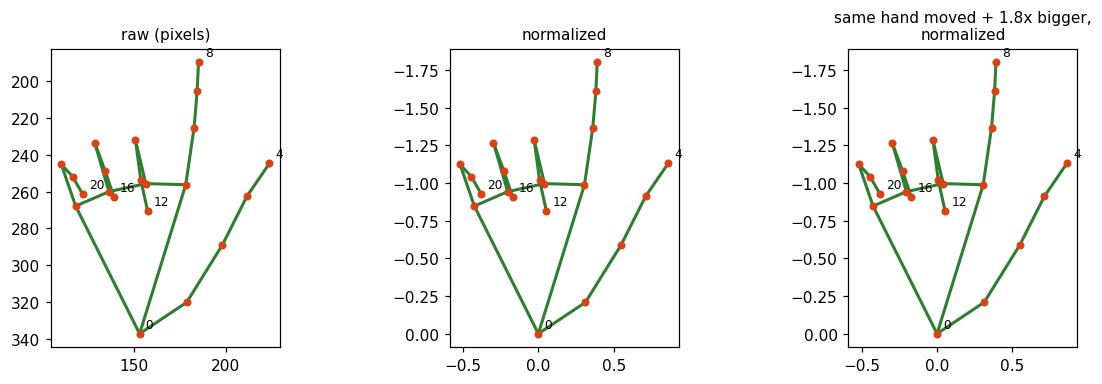

identical after normalization: True


In [4]:
feat = normalize_landmarks(raw, "Right")
pts = feat.reshape(21, 3)
print("63 numbers, first 9:", np.round(feat[:9], 3))
print("wrist:", pts[0], "| wrist->middle knuckle length:", round(float(np.linalg.norm(pts[9])), 3))

fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
draw(axes[0], raw, "raw (pixels)")
draw(axes[1], pts, "normalized")
shifted_and_scaled = raw * 1.8 + np.array([150, -60, 0])
draw(axes[2], normalize_landmarks(shifted_and_scaled, "Right").reshape(21, 3), "same hand moved + 1.8x bigger,\nnormalized")
plt.tight_layout(); plt.show()
print("identical after normalization:", np.allclose(feat, normalize_landmarks(shifted_and_scaled, "Right")))

## Every letter, my hand vs. the reference model

The reference hands are generated by a tiny finger-joint model (`aslcv.reference`), in the same 21-point format.
Real hands differ from the drawings (e.g. a real X hook is far less bent), which is why the tutor learns its
expected shapes from real data instead (journal 10).

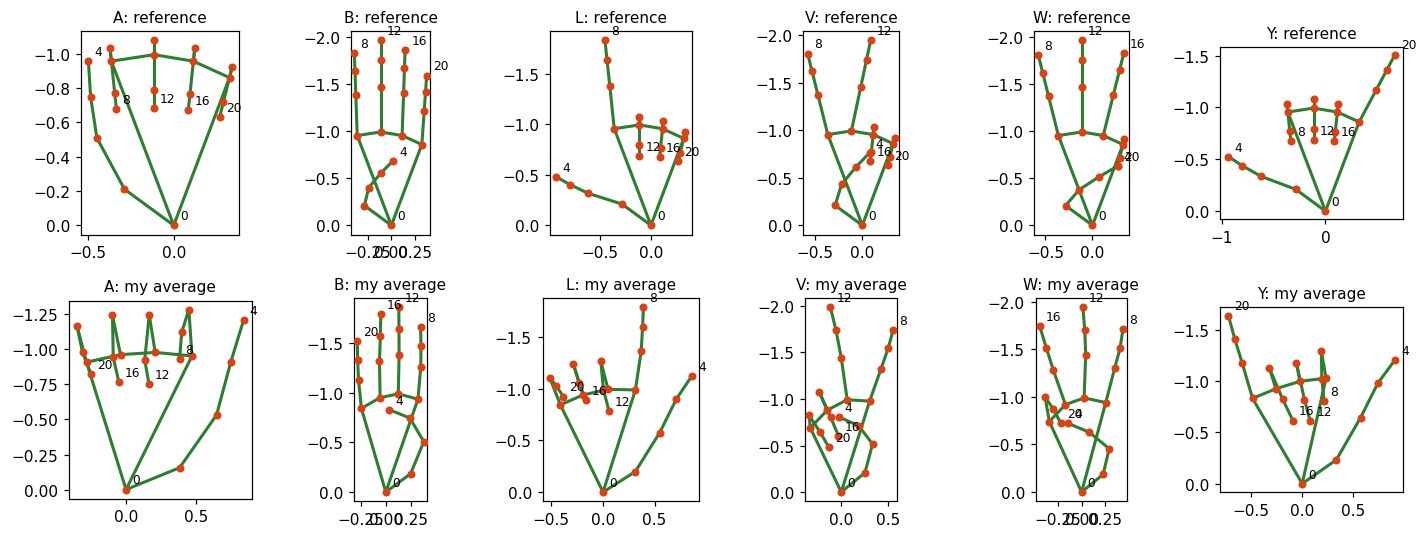

In [5]:
from aslcv.reference import reference_pose
fig, axes = plt.subplots(2, 6, figsize=(13, 5))
for col, letter in enumerate("ABLVWY"):
    mine = s4["X"][s4["y"] == letter].mean(0).reshape(21, 3)
    draw(axes[0, col], normalize_landmarks(reference_pose(letter)).reshape(21, 3), f"{letter}: reference")
    draw(axes[1, col], mine, f"{letter}: my average")
plt.tight_layout(); plt.show()